In [1]:
%load_ext autoreload
%autoreload 2

from jaxtyping import install_import_hook

with install_import_hook("nazwa_twojego_pakietu", "beartype.beartype"):
    from Projekt.delaunay import Triangulation
    from Projekt.utils.csvIO import load_points_from_csv, save_points_to_csv, save_triangulation_to_csv
    from Projekt.utils.generators.generate_points import generate_uniform_points
    from Projekt.utils.generators.mouse_point_generator import  get_points_interactive
    from bitalg.visualizer.main import Visualizer
    import numpy as np

# Wybór generowania punktów

# 1. Losowo

In [17]:
points = generate_uniform_points(-10,10,6)

# 2. Zdefiniowanie w kodzie

In [4]:
points = np.array([[ 6.42647586, -8.53769683],
                   [1.50583384, 2.0546824 ],
                   [1.97936182, 5.52998142],
                   [-1.01798849, -6.93659749],
                   [ 5.3814328,  -2.66880444],
                   [-8.62529473, -6.77310924]])

# 3. Interaktywny wybór

In [6]:
%matplotlib tk
x_min = -10
x_max = 10
y_min= -10
y_max = 10

points = get_points_interactive(x_min,x_max,y_min,y_max)
print(points)

[]


In [5]:
points = np.array(points)

# Możliwosć zapisu punktów do wybranego przez siebie pliku w formacie csv

In [ ]:
filename = "edge_case"

In [ ]:
save_points_to_csv(points,"Projekt/points/"+filename+".csv")

Pomyślnie zapisano 6 punktów do Projekt/points/edge_case


# Wczytanie punktów wcześniej zapisanych w pliku

In [ ]:
points = load_points_from_csv("Projekt/points/"+filename+".csv")

Pomyślnie wczytano 6 punktów z Projekt/points/edge_case


# Wizualizacja punktów na których przeprowadzana będzie triangulacja

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


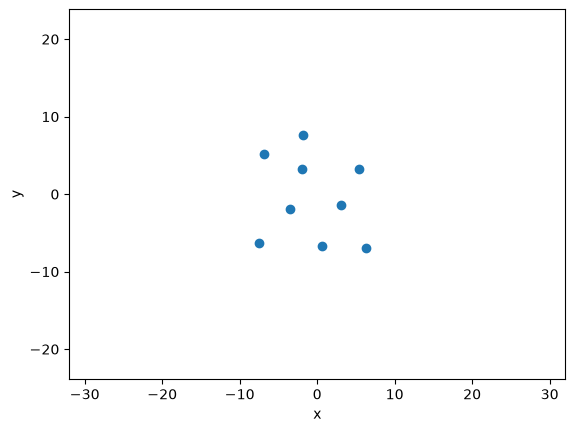

In [7]:
%matplotlib inline
vis = Visualizer()
x_min = -10
x_max = 10
y_min= -10
y_max = 10
vis.set_limits((3.2*x_min,3.2*x_max),(3.2*y_min,3.2*y_max))
vis.add_point(points)
vis.axis_equal()
vis.show()
vis.clear()
vis.axis_equal()
vis.set_limits((-30,30),(-30,30))

# Wybór wariantu agorytmu wyszukiwania trójkąta

In [ ]:
from Projekt.utils.custom_types import variants

#variant: variants = "JaW"
variant: variants = "Graph"

In [11]:
triangulation = Triangulation(points,variant,vis)
triangulation.triangulate()
triangles = triangulation.get_triangulation()

Dodawanie punktu 0: [ 6.42647586 -8.53769683]
Dodawanie punktu 1: [1.50583384 2.0546824 ]
Dodawanie punktu 2: [1.97936182 5.52998142]
Dodawanie punktu 3: [-1.01798849 -6.93659749]
Dodawanie punktu 4: [ 5.3814328  -2.66880444]
Dodawanie punktu 5: [-8.62529473 -6.77310924]


# Możliwość zapisu wynikowej triangulacji do csv

In [ ]:
save_triangulation_to_csv(triangles,"Projekt/triangulations/"+filename+".csv")

# Wizualizacja triangulacji

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


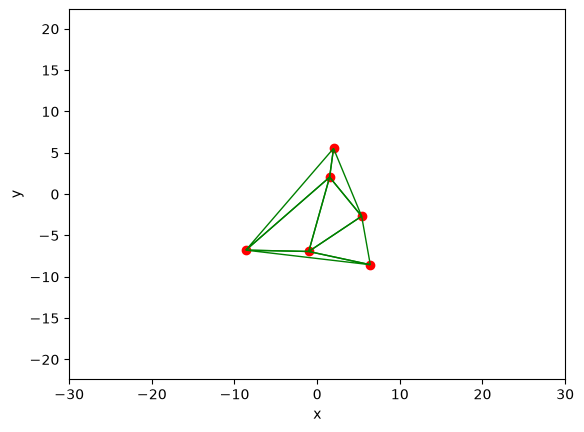

In [8]:
vis.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


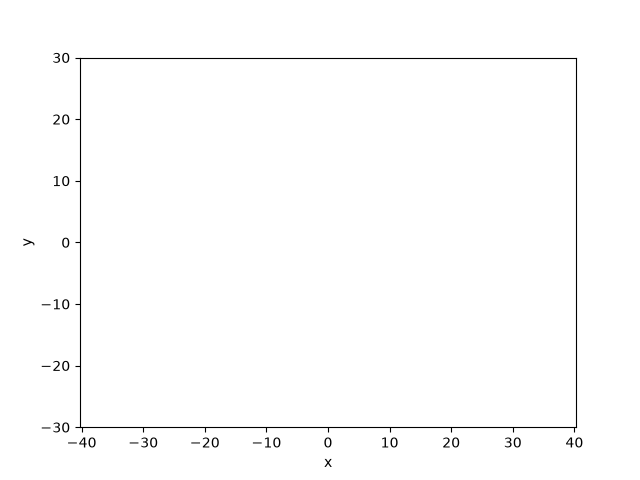

In [9]:
vis.show_gif()